## I. Convergence

In [1]:
import wandb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

api = wandb.Api()

run_1 = api.run("my-ku-org/placemeent/5ympxbnu")
run_2 = api.run("my-ku-org/placemeent/ba5ee0bz")
run_3 = api.run("my-ku-org/placemeent/9jw1nd1j")
run_4 = api.run("my-ku-org/placemeent/b9opf3p7")

In [3]:
run_4.config

{'lr': 0.0003,
 'tau': 0.005,
 'alpha': 0.2,
 'gamma': 0.99,
 'use_llm': True,
 'ckpt_dir': 'models',
 'run_name': '0729_085632',
 'ckpt_freq': 100,
 'max_steps': 200,
 'batch_size': 64,
 'buffer_size': 100000,
 'max_episodes': 30000,
 'exploration_rate': 0.5}

In [22]:
keys=["global_step", "episode", "reward", "latency", "lb", "ru"]
r1 = run_1.history(keys=keys, samples=1000)
r2 = run_2.history(keys=keys, samples=1000)
r3 = run_3.history(keys=keys, samples=1000)

In [ ]:
def episode_(df: pd.DataFrame):
    df = df.copy()
    df.loc[0, "episode"] = 0.0  # to interpolate correctly
    df["episode_"] = df["episode"].interpolate(method="linear").round()
    return df

def running_mean(x: pd.Series, n=100):
    return x.rolling(window=n, min_periods=1).mean()

def crop(df: pd.DataFrame, c: float):
    return df[df["episode_"] <= c]

In [26]:
r1 = episode_(r1)
r2 = episode_(r2)
r3 = episode_(r3)

### I.a. cumulative reward

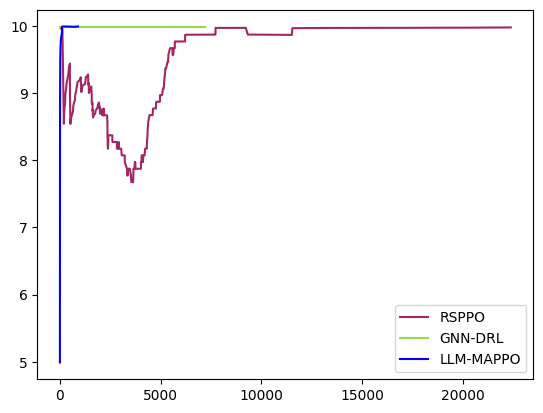

In [ ]:
key = "reward"
colors = ["#A12864", "#98DA4C", "#0000ff"]
labels = ["RSPPO", "GNN-DRL","LLM-MAPPO", "uDDRL"]
at = np.inf #5000
plt.plot(crop(r1, at)["episode_"][1:], running_mean(crop(r1,at)[key], n=100)[1:], color=colors[0], label=labels[0])
plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
plt.legend()
plt.show()

### I.b. End-to-end latency

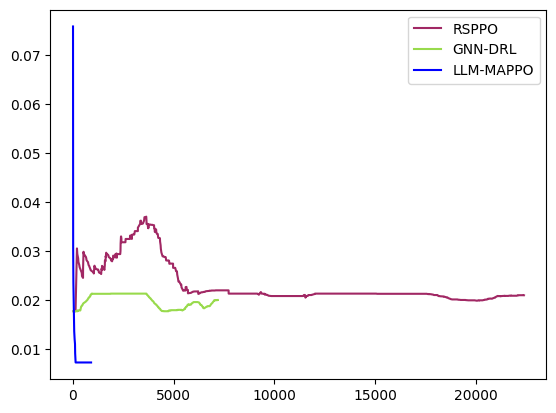

In [30]:
key = "latency"
colors = ["#A12864", "#98DA4C", "#0000ff"]
labels = ["RSPPO", "GNN-DRL","LLM-MAPPO"]
at = np.inf #5000
plt.plot(crop(r1, at)["episode_"][1:], running_mean(crop(r1,at)[key], n=100)[1:], color=colors[0], label=labels[0])
plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
plt.legend()
plt.show()

### I.c. QoS load balancing index

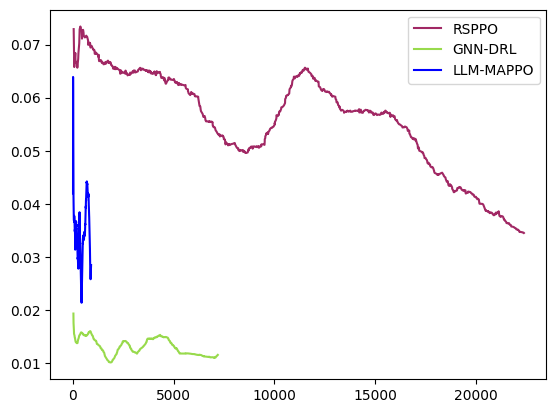

In [31]:
key = "lb"
colors = ["#A12864", "#98DA4C", "#0000ff"]
labels = ["RSPPO", "GNN-DRL","LLM-MAPPO"]
at = np.inf #5000
plt.plot(crop(r1, at)["episode_"][1:], running_mean(crop(r1,at)[key], n=100)[1:], color=colors[0], label=labels[0])
plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
plt.legend()
plt.show()

### I.d. SLA violation rate(%)

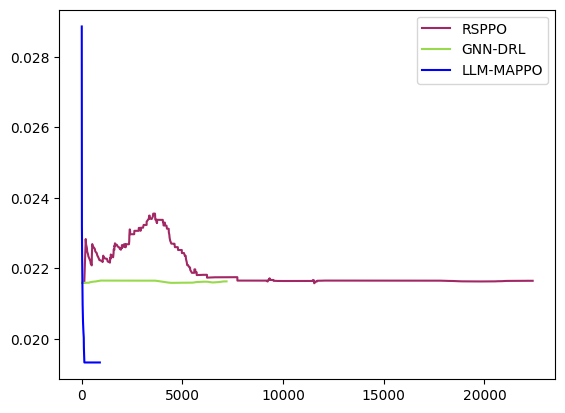

In [32]:
key = "ru"
colors = ["#A12864", "#98DA4C", "#0000ff"]
labels = ["RSPPO", "GNN-DRL","LLM-MAPPO"]
at = np.inf #5000
plt.plot(crop(r1, at)["episode_"][1:], running_mean(crop(r1,at)[key], n=100)[1:], color=colors[0], label=labels[0])
plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
plt.legend()
plt.show()

## II. Arrival Rate

### II.a. convergence time

### II.b. End to end latency

### II.c. Load balancing index

### II.d. SLA violation rate(%)

## III. System Complexity (N_MS)

### III.a. convergence time

### III.b. End to end latency

### III.c. Load balancing index

### III.d. SLA violation rate(%)

## IV. System adaptation

### IV.a. service recovery after edge node failures

### IV.b. Adaptation speed to suddent traffic bursts

# MORE MORE PLOTS :-()